# Práctica 4: Neurona simple con NumPy y Matplotlib

## Objetivo
En este cuaderno retomaremos el primer modelo lineal ($y = wx$), pero esta vez implementando las bibliotecas especializadas de Python para cálculo numérico y visualización[cite: 57]. NumPy se utilizará para trabajar directamente con arreglos numéricos y realizar operaciones vectorizadas, mientras que Matplotlib permitirá observar gráficamente la evolución del peso y del error promedio durante el entrenamiento[cite: 57].

## Datos de Entrenamiento Vectorizados
Los datos se almacenarán ahora como arreglos de NumPy (`np.array`)[cite: 57]:
* Entradas ($x$): `[1, 2, 3, 4]`[cite: 57]
* Salidas esperadas ($t$): `[2, 4, 6, 8]`[cite: 57]

## Modelo Matemático y Operaciones sobre Arreglos

El modelo se conserva idéntico:
$$y = wx$$

### La ventaja de la Vectorización con NumPy
Al utilizar NumPy, ya no es necesario recorrer los datos elemento por elemento con ciclos `for` o listas por comprensión[cite: 60]. Las operaciones matemáticas se aplican simultáneamente a todo el vector de datos. 
Las predicciones se obtienen directamente multiplicando el peso por el arreglo de entradas:
$$p = w \cdot x$$

Los errores se calculan con una sola resta de arreglos:
$$e = t - p$$

El error promedio de la época se obtiene utilizando la función nativa `np.mean()` sobre el arreglo de errores, optimizando significativamente la ejecución computacional[cite: 60].


EPOCA 1
Entrada:  1.0 | Target:   2.0 | Prediccion:   0.1000 | Error:   1.9000
Entrada:  2.0 | Target:   4.0 | Prediccion:   0.2000 | Error:   3.8000
Entrada:  3.0 | Target:   6.0 | Prediccion:   0.3000 | Error:   5.7000
Entrada:  4.0 | Target:   8.0 | Prediccion:   0.4000 | Error:   7.6000
Peso antes de actualizar: 0.100000
Error promedio: 4.750000
Peso despues de actualizar: 0.575000

EPOCA 2
Entrada:  1.0 | Target:   2.0 | Prediccion:   0.5750 | Error:   1.4250
Entrada:  2.0 | Target:   4.0 | Prediccion:   1.1500 | Error:   2.8500
Entrada:  3.0 | Target:   6.0 | Prediccion:   1.7250 | Error:   4.2750
Entrada:  4.0 | Target:   8.0 | Prediccion:   2.3000 | Error:   5.7000
Peso antes de actualizar: 0.575000
Error promedio: 3.562500
Peso despues de actualizar: 0.931250

EPOCA 3
Entrada:  1.0 | Target:   2.0 | Prediccion:   0.9313 | Error:   1.0687
Entrada:  2.0 | Target:   4.0 | Prediccion:   1.8625 | Error:   2.1375
Entrada:  3.0 | Target:   6.0 | Prediccion:   2.7938 | Error:   3.206

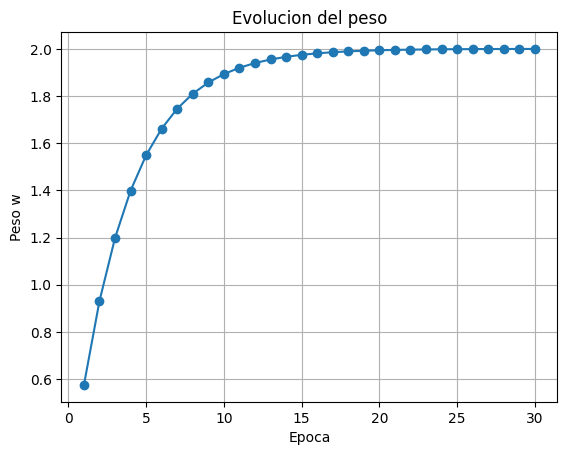

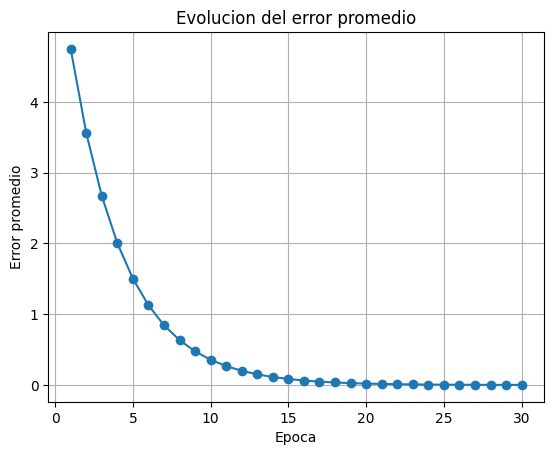

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

inputs = np.array([1, 2, 3, 4], dtype=float)
targets = np.array([2, 4, 6, 8], dtype=float)

w = 0.1
learning_rate = 0.1
epochs = 30
pause_time = 0.2

weight_history = []
error_history = []

for epoch in range(epochs):
    
    predictions = w * inputs
    
    errors = targets - predictions
    
    error_mean = np.mean(errors)
    
    print("\n" + "=" * 60)
    print(f"EPOCA {epoch + 1}")
    print("=" * 60)
    
    for i, t, p, e in zip(inputs, targets, predictions, errors):
        print(
            f"Entrada: {i:>4.1f} | "
            f"Target: {t:>5.1f} | "
            f"Prediccion: {p:>8.4f} | "
            f"Error: {e:>8.4f}"
        )
        
    print(f"Peso antes de actualizar: {w:.6f}")
    print(f"Error promedio: {error_mean:.6f}")
    
    w += learning_rate * error_mean
    
    print(f"Peso despues de actualizar: {w:.6f}")
    
    weight_history.append(w)
    error_history.append(error_mean)
    
    time.sleep(pause_time)

test_inputs = np.array([5, 6], dtype=float)
test_targets = np.array([10, 12], dtype=float)

test_predictions = w * test_inputs

print("\n" + "=" * 60)
print("PRUEBA FINAL")
print("=" * 60)

for i, t, p in zip(test_inputs, test_targets, test_predictions):
    print(
        f"Entrada: {i:>4.1f} | "
        f"Target: {t:>5.1f} | "
        f"Prediccion: {p:>8.4f}"
    )

plt.figure()
plt.plot(range(1, epochs + 1), weight_history, marker="o")
plt.xlabel("Epoca")
plt.ylabel("Peso w")
plt.title("Evolucion del peso")
plt.grid()
plt.show()

plt.figure()
plt.plot(range(1, epochs + 1), error_history, marker="o")
plt.xlabel("Epoca")
plt.ylabel("Error promedio")
plt.title("Evolucion del error promedio")
plt.grid()
plt.show()

## Análisis de Resultados y Visualización

La implementación con bibliotecas de cálculo científico nos deja dos conclusiones importantes:
1. **Eficiencia del código (NumPy):** Se comprobó que NumPy permite realizar operaciones directamente sin construir listas elemento por elemento, como se evidencia en la limpieza y brevedad del código matemático[cite: 60].
2. **Análisis Gráfico (Matplotlib):** 
    * En la gráfica de *Evolución del peso*, se observa claramente cómo el peso se aproxima progresivamente al valor esperado ($w \approx 2$) trazando una curva asintótica suave[cite: 60].
    * En la gráfica de *Evolución del error promedio*, se evidencia visualmente la disminución progresiva del error, el cual arranca cerca de 5.0 y decae de forma exponencial hasta estabilizarse en 0 tras las 30 épocas de entrenamiento[cite: 60, 61].